# Actuator command vs angular velocity

One plot per body axis: the actuator command against the measured angular rate.

**Note on what "actuator" means here.** These logs contain no motor outputs — the firmware
(`pid_esc_rx_gyro_v10`) logs the PID term contributions but not the mixer output or the ESC
commands. The closest available actuator signal is the per-axis controller output

```
u_axis = p_axis + i_axis + d_axis
```

which is what `motor_mix.h` receives before it is combined with throttle and distributed to
the four motors. So this is the *demanded* torque per axis, not measured motor action.

Armed samples only.

In [1]:
# ============================================================
# Setup
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


# ------------------------------------------------------------
# Locate logs (repo-relative)
# ------------------------------------------------------------

HERE = Path.cwd()

LOG_DIR = (HERE / ".." / "sample-flight-logs").resolve()

if not LOG_DIR.is_dir():
    LOG_DIR = next(
        p for p in [HERE, *HERE.parents]
        if (p / "software" / "sample-flight-logs").is_dir()
    ) / "software" / "sample-flight-logs"

LOG_FILES = sorted(LOG_DIR.glob("logs*.csv"))

AXES = ["Roll", "Pitch", "Yaw"]

COLS = (
    ["time_us", "armSwitch", "frameLost", "rxThrottle"]
    + [f"gyro{a}" for a in AXES]
    + [f"{t}{a}" for a in AXES for t in "pid"]
)

DTYPES = {c: np.float32 for c in COLS}
DTYPES["time_us"] = np.int64
DTYPES["armSwitch"] = np.uint8
DTYPES["frameLost"] = np.uint8


# motor_mix.h constants
MOTOR_IDLE = 130
MOTOR_MAX = 2047

U_LIMIT = {"Roll": 1000.0, "Pitch": 1000.0, "Yaw": 2000.0}

MOTORS = ["m1", "m2", "m3", "m4"]

# Sign of (roll, pitch, yaw) per motor, from computePower()
MIX = {
    "m1": (-1, -1, -1),
    "m2": (-1, +1, +1),
    "m3": (+1, -1, +1),
    "m4": (+1, +1, -1),
}


def load(path):
    """Load one log, keep armed samples, add actuator command
    per axis and the reconstructed motor commands."""

    df = pd.read_csv(path, usecols=COLS, dtype=DTYPES)

    df["t"] = df["time_us"] / 1e6

    for a in AXES:
        df[f"u{a}"] = (
            (df[f"p{a}"] + df[f"i{a}"] + df[f"d{a}"])
            .clip(-U_LIMIT[a], U_LIMIT[a])
        )

    # --------------------------------------------------------
    # Reconstruct computePower() exactly
    # --------------------------------------------------------

    thr = MOTOR_IDLE + df["rxThrottle"] * (MOTOR_MAX - MOTOR_IDLE)

    for m, (sr, sp, sy) in MIX.items():
        df[m] = (
            thr
            + sr * df["uRoll"]
            + sp * df["uPitch"]
            + sy * df["uYaw"]
        ).clip(MOTOR_IDLE, MOTOR_MAX)

    # On a dropped RC frame the firmware re-sent prev_motor* instead of
    # calling computePower(), so the reconstruction is invalid there.
    bad = df["frameLost"] > 0
    df.loc[bad, MOTORS] = np.nan

    df = df[df["armSwitch"] == 1].reset_index(drop=True)

    return df


logs = {f.stem: load(f) for f in LOG_FILES}

for name, df in logs.items():
    print(
        f"{name}: {len(df):,} armed samples, "
        f"{df['t'].iloc[-1] - df['t'].iloc[0]:.1f} s, "
        f"{int(df['m1'].isna().sum())} invalid (frameLost)"
    )

logs0306: 66,536 armed samples, 66.5 s, 0 invalid (frameLost)
logs0311: 122,361 armed samples, 122.4 s, 0 invalid (frameLost)
logs0326: 182,408 armed samples, 182.4 s, 0 invalid (frameLost)
logs0330: 191,466 armed samples, 191.5 s, 0 invalid (frameLost)


## Time series

Actuator command (blue, left axis) and angular rate (orange, right axis), one subplot per
axis, one figure per flight.

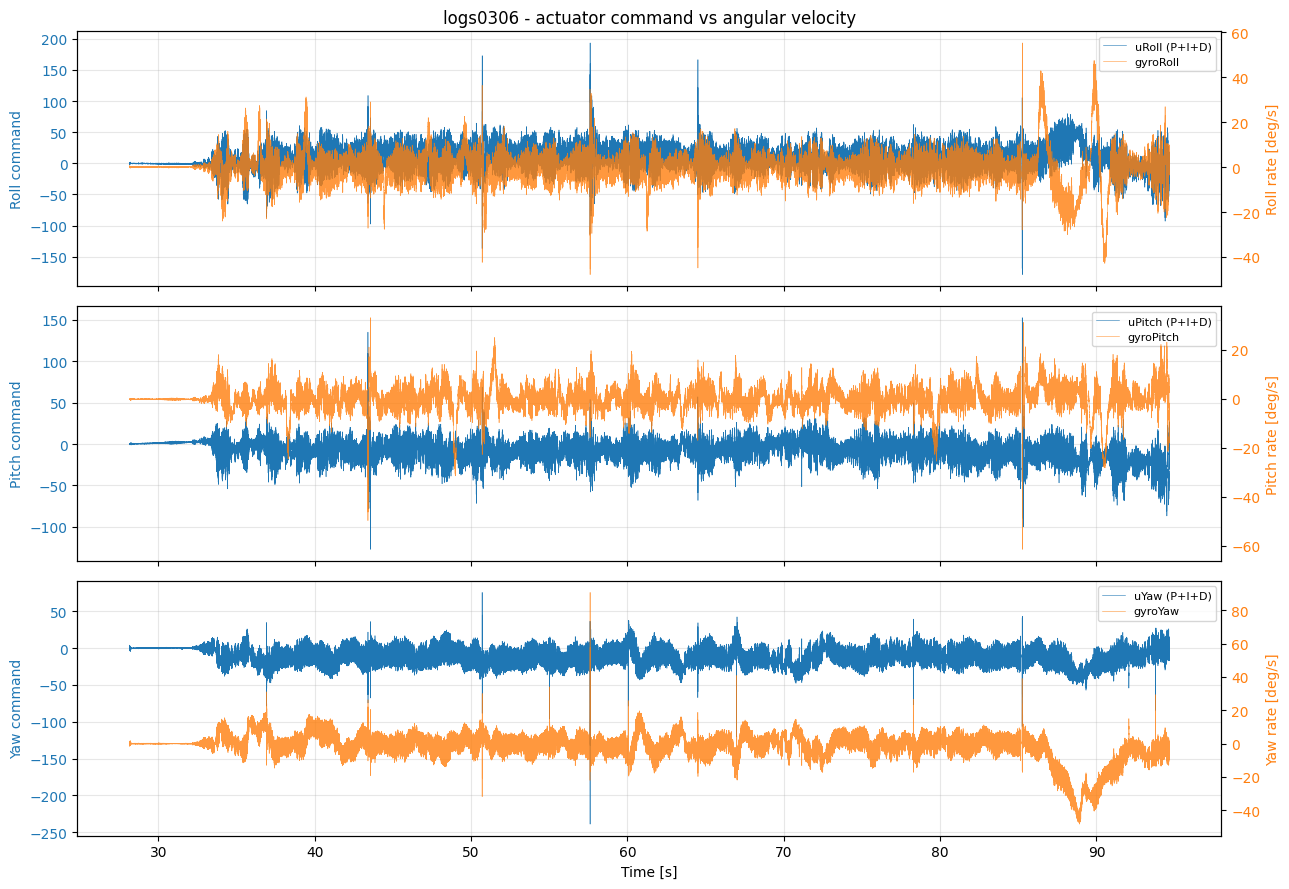

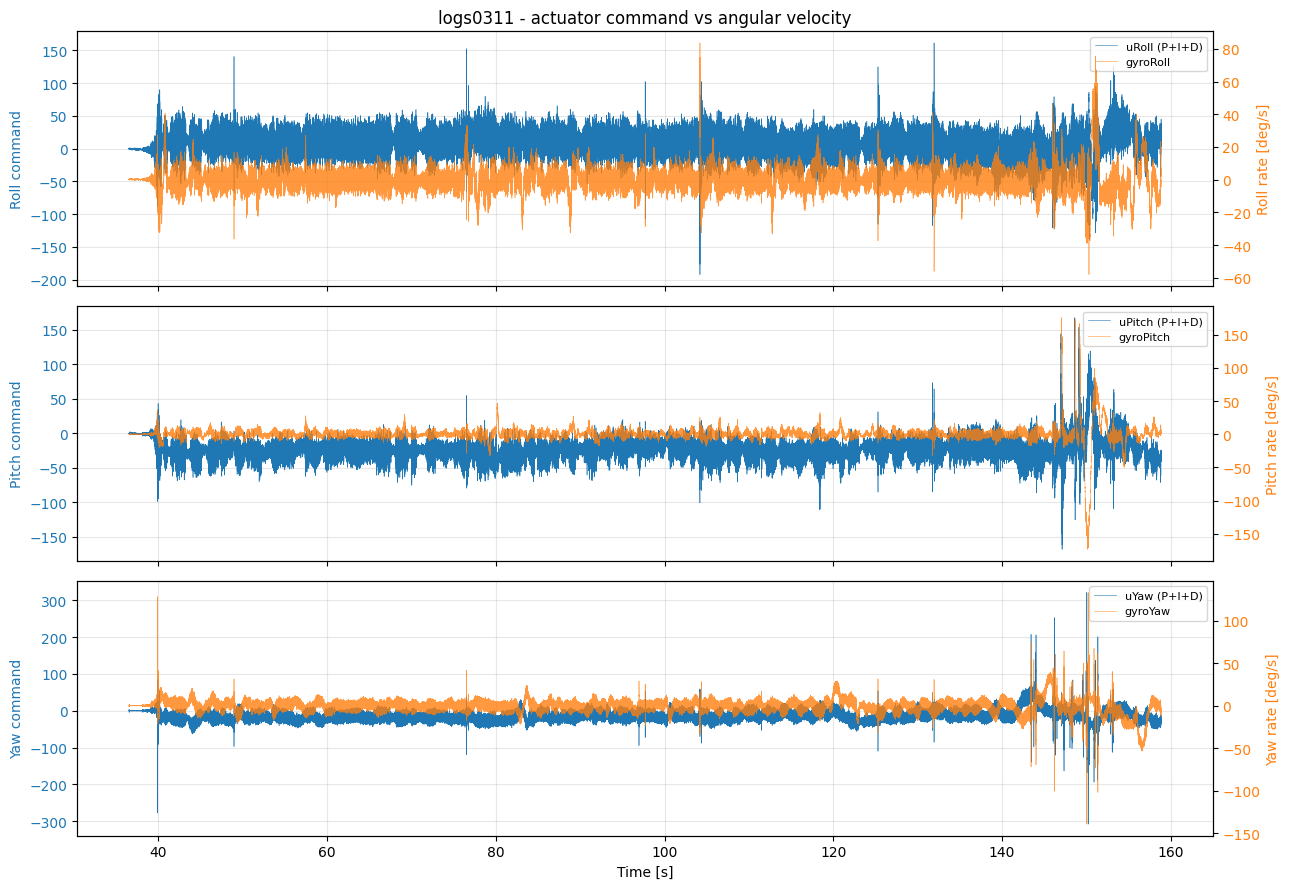

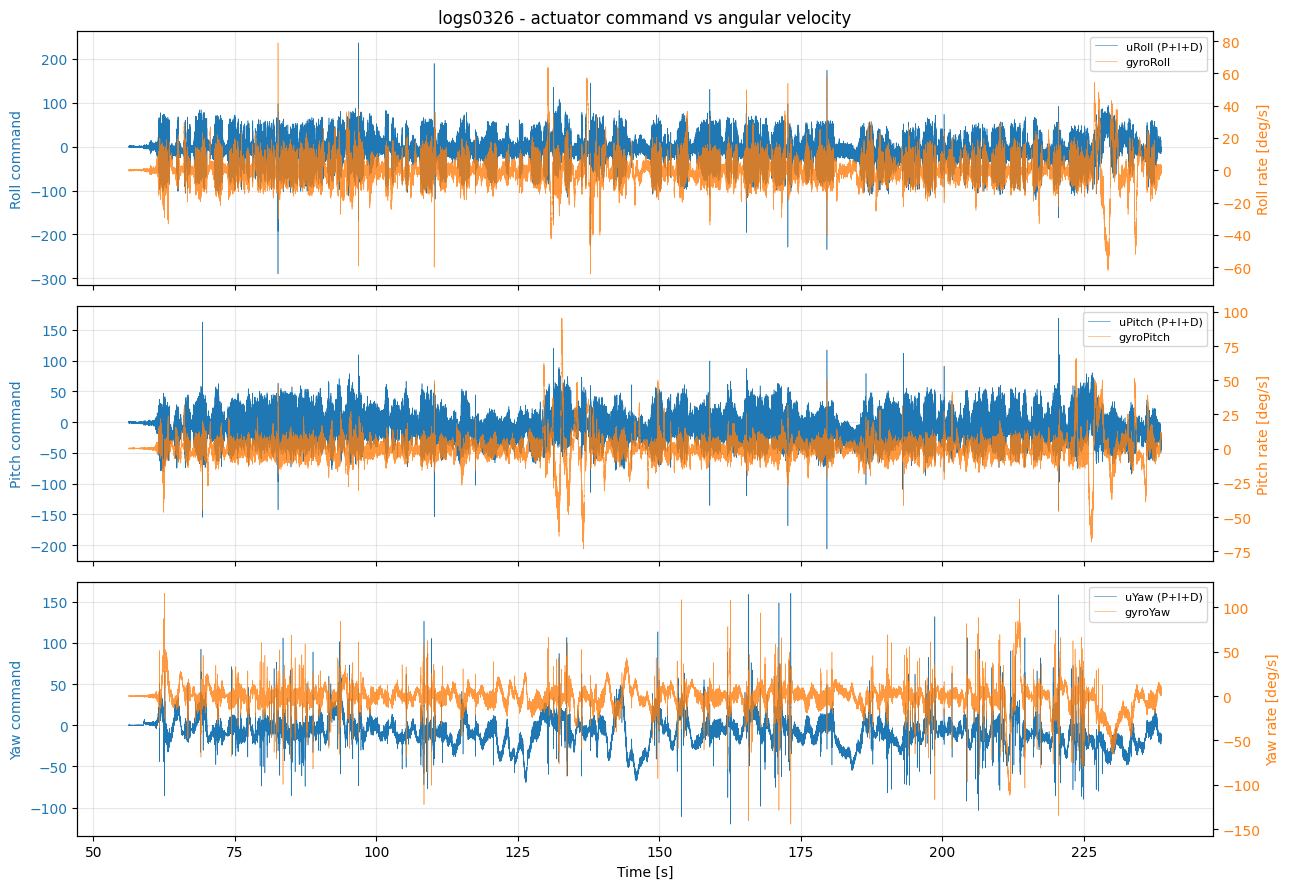

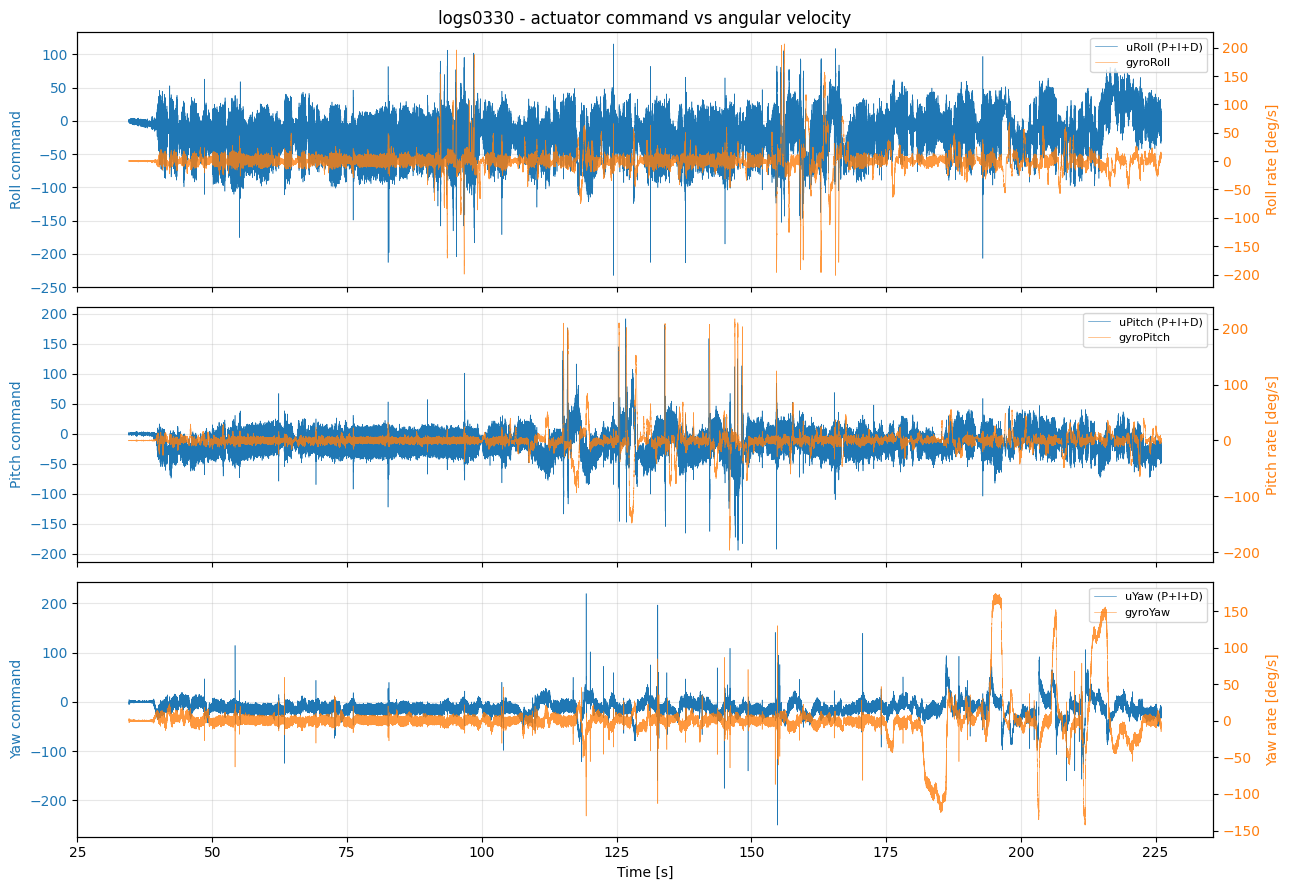

In [2]:
# ============================================================
# Actuator command vs rate, per axis
# ============================================================

for name, df in logs.items():

    fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

    for ax, a in zip(axs, AXES):

        ax.plot(df["t"], df[f"u{a}"], lw=0.4,
                color="tab:blue", label=f"u{a} (P+I+D)")
        ax.set_ylabel(f"{a} command", color="tab:blue")
        ax.tick_params(axis="y", labelcolor="tab:blue")

        ax2 = ax.twinx()
        ax2.plot(df["t"], df[f"gyro{a}"], lw=0.4,
                 color="tab:orange", alpha=0.8, label=f"gyro{a}")
        ax2.set_ylabel(f"{a} rate [deg/s]", color="tab:orange")
        ax2.tick_params(axis="y", labelcolor="tab:orange")
        ax2.grid(False)

        lines = ax.get_lines() + ax2.get_lines()
        ax.legend(lines, [l.get_label() for l in lines],
                  loc="upper right", fontsize=8)

    axs[0].set_title(f"{name} - actuator command vs angular velocity")
    axs[-1].set_xlabel("Time [s]")

    fig.tight_layout()
    plt.show()

## Zoom

The same signals over 2 s, where the phase relationship between command and rate is
actually visible.

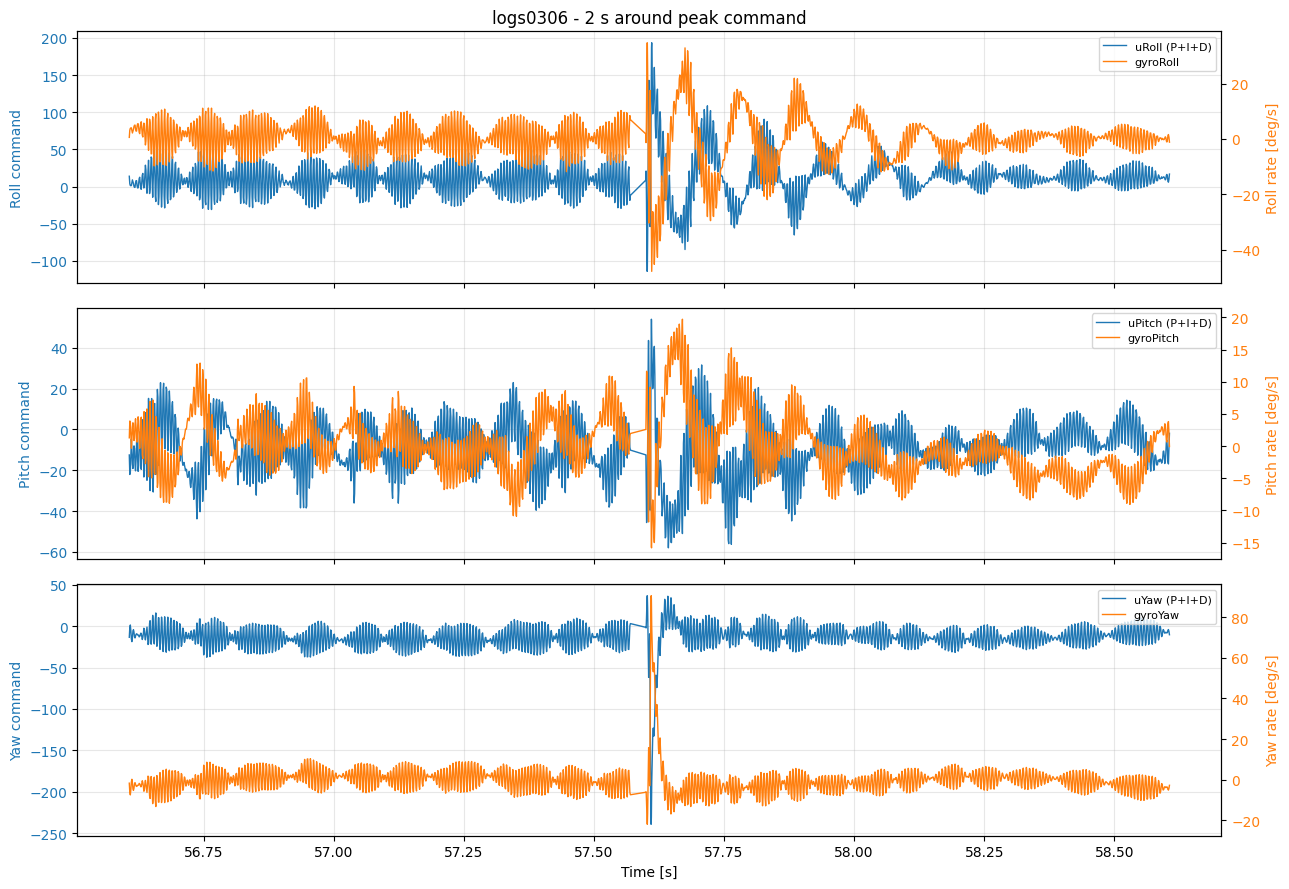

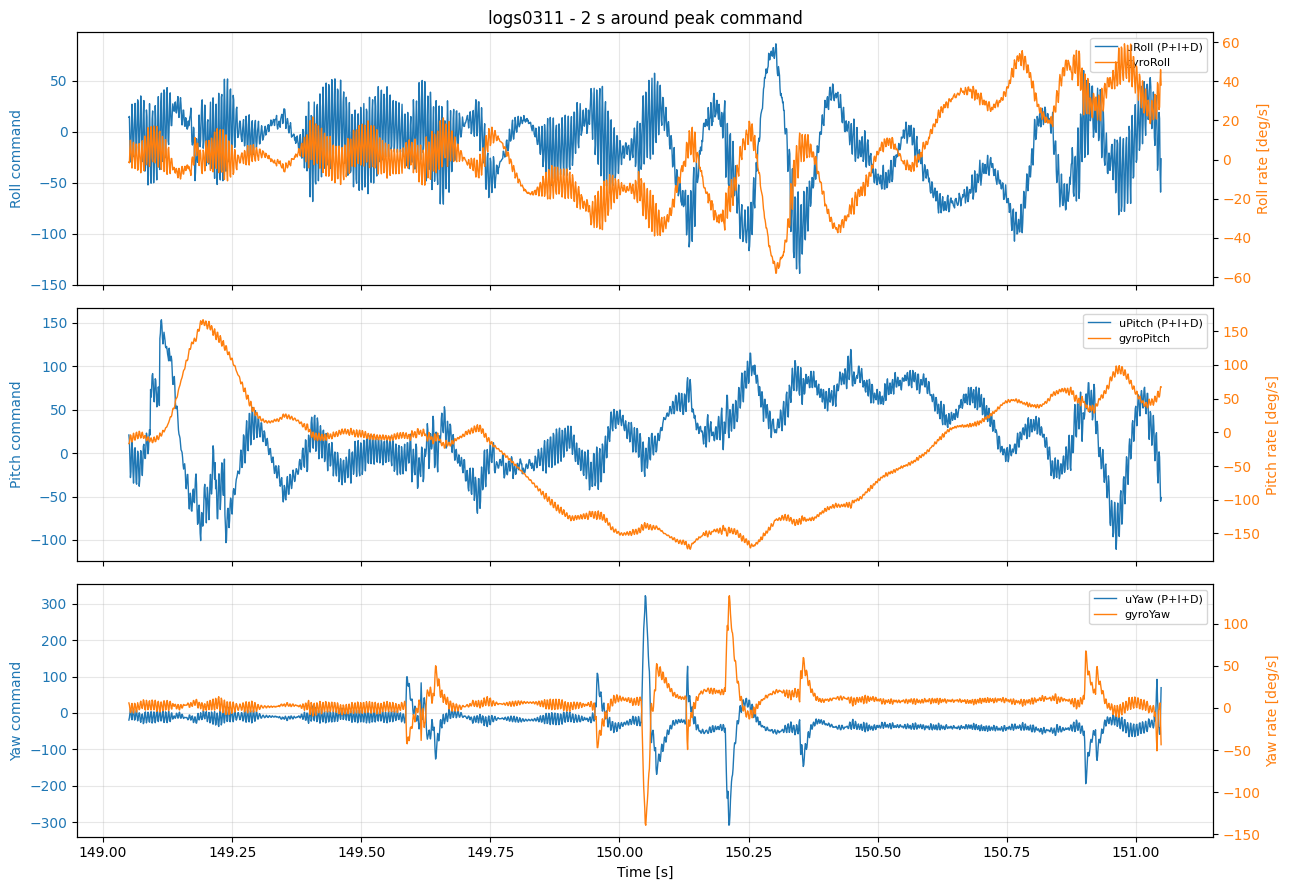

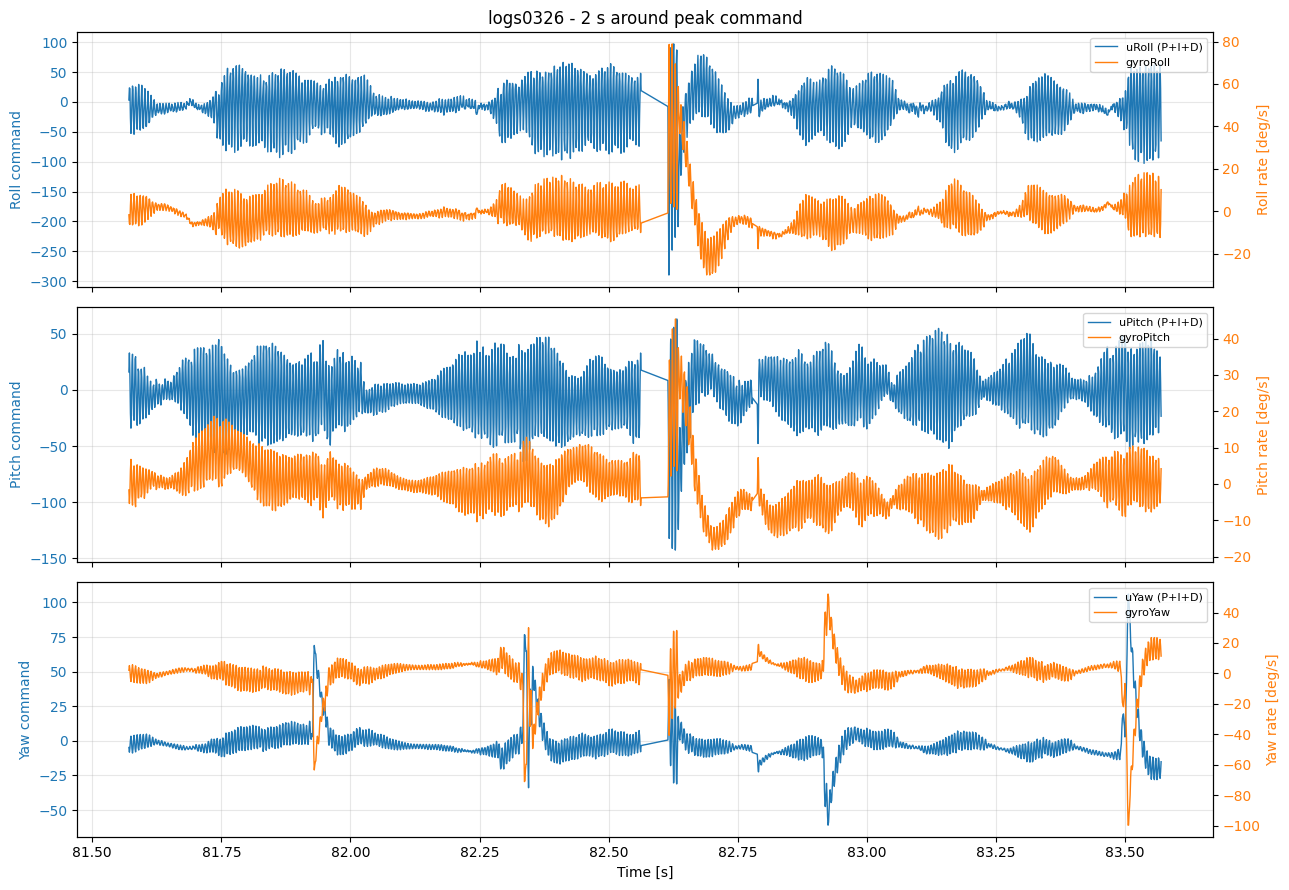

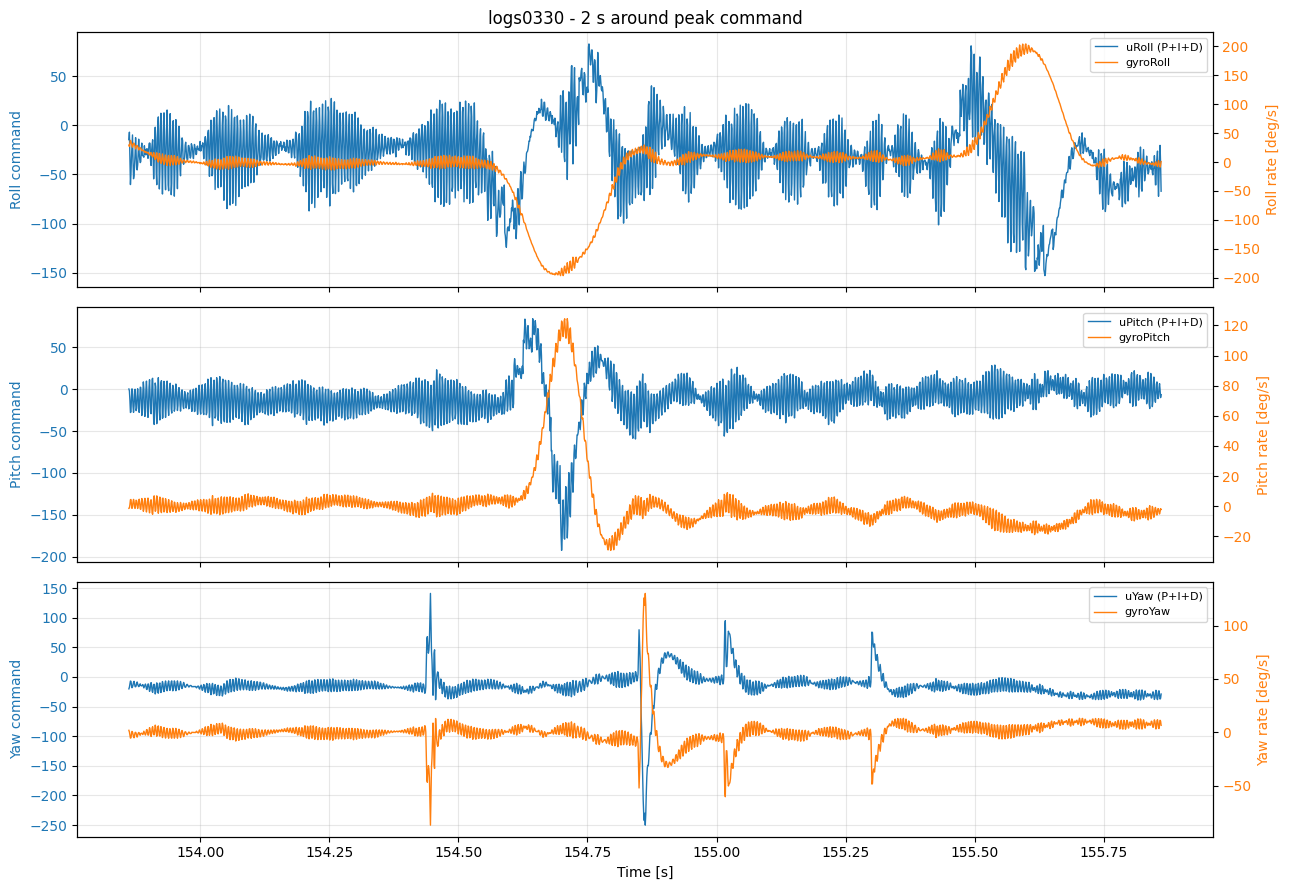

In [3]:
# ============================================================
# 2 s window
# ============================================================

WINDOW_S = 2.0

for name, df in logs.items():

    # Centre on the largest actuator command in the flight
    i = int(df[[f"u{a}" for a in AXES]].abs().max(axis=1).idxmax())
    half = int(WINDOW_S / 2 * 1000)
    sl = slice(max(0, i - half), min(len(df), i + half))

    fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

    for ax, a in zip(axs, AXES):

        ax.plot(df["t"][sl], df[f"u{a}"][sl], lw=1.0,
                color="tab:blue", label=f"u{a} (P+I+D)")
        ax.set_ylabel(f"{a} command", color="tab:blue")
        ax.tick_params(axis="y", labelcolor="tab:blue")

        ax2 = ax.twinx()
        ax2.plot(df["t"][sl], df[f"gyro{a}"][sl], lw=1.0,
                 color="tab:orange", label=f"gyro{a}")
        ax2.set_ylabel(f"{a} rate [deg/s]", color="tab:orange")
        ax2.tick_params(axis="y", labelcolor="tab:orange")
        ax2.grid(False)

        lines = ax.get_lines() + ax2.get_lines()
        ax.legend(lines, [l.get_label() for l in lines],
                  loc="upper right", fontsize=8)

    axs[0].set_title(f"{name} - {WINDOW_S:g} s around peak command")
    axs[-1].set_xlabel("Time [s]")

    fig.tight_layout()
    plt.show()

## Motor commands and gyro

`m1..m4` are reconstructed from `rxThrottle` and the logged PID terms by replaying
`computePower()`:

```
thr = 130 + rxThrottle * (2047 - 130)
m1  = clip(thr - uRoll - uPitch - uYaw, 130, 2047)
m2  = clip(thr - uRoll + uPitch + uYaw, 130, 2047)
m3  = clip(thr + uRoll - uPitch + uYaw, 130, 2047)
m4  = clip(thr + uRoll + uPitch - uYaw, 130, 2047)
```

Ticks where `frameLost` fired are blanked: there the firmware re-sent `prev_motor*`
instead of calling the mixer, so the reconstruction does not hold.

Top panel: the four DShot commands actually sent to the ESCs.
Bottom panel: the three measured body rates.

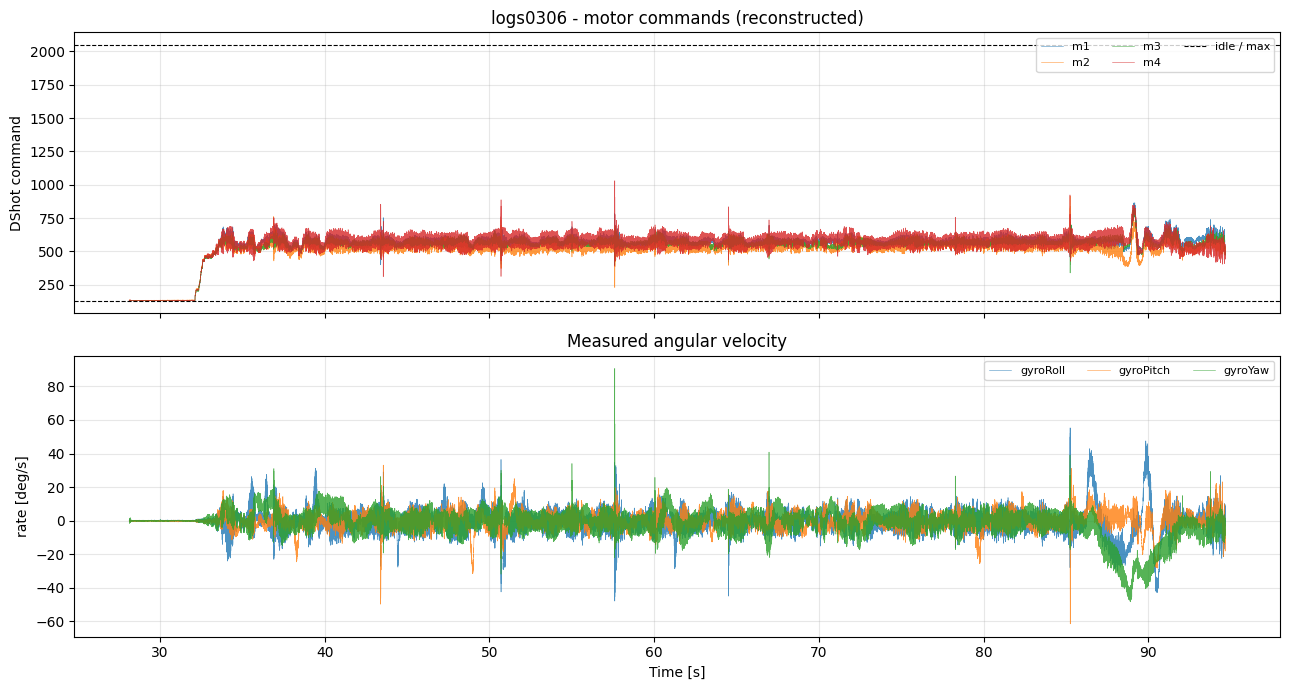

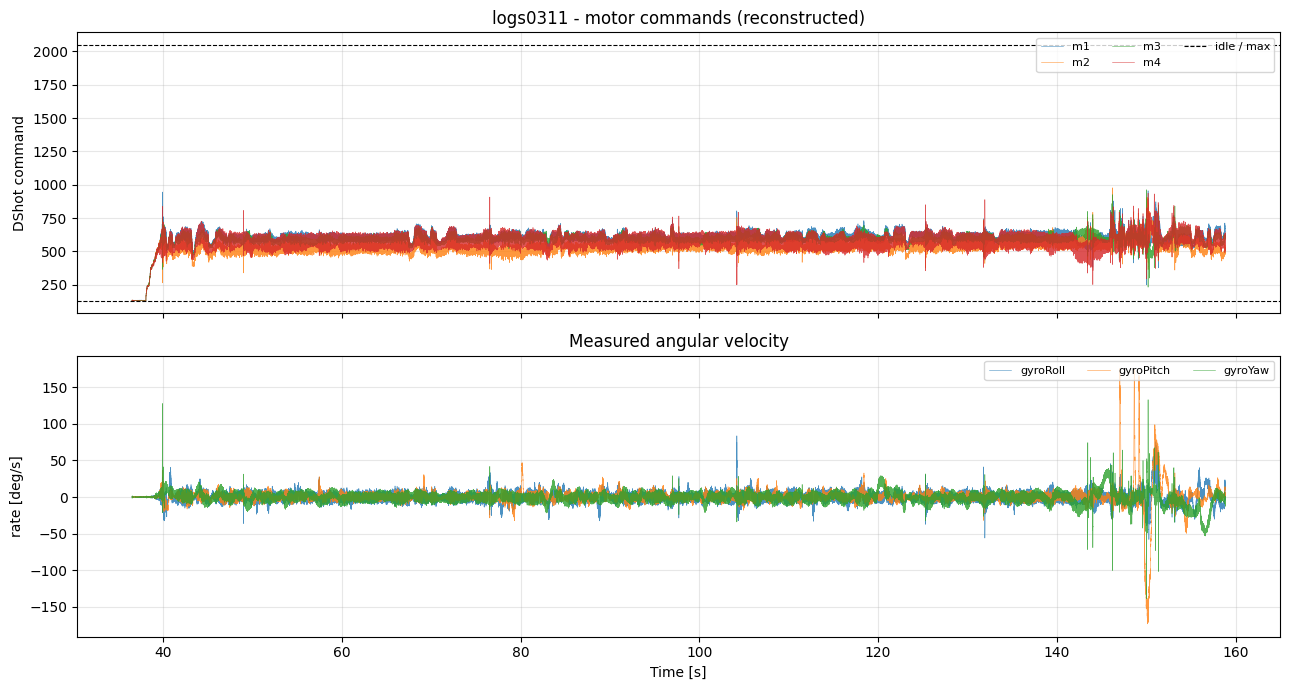

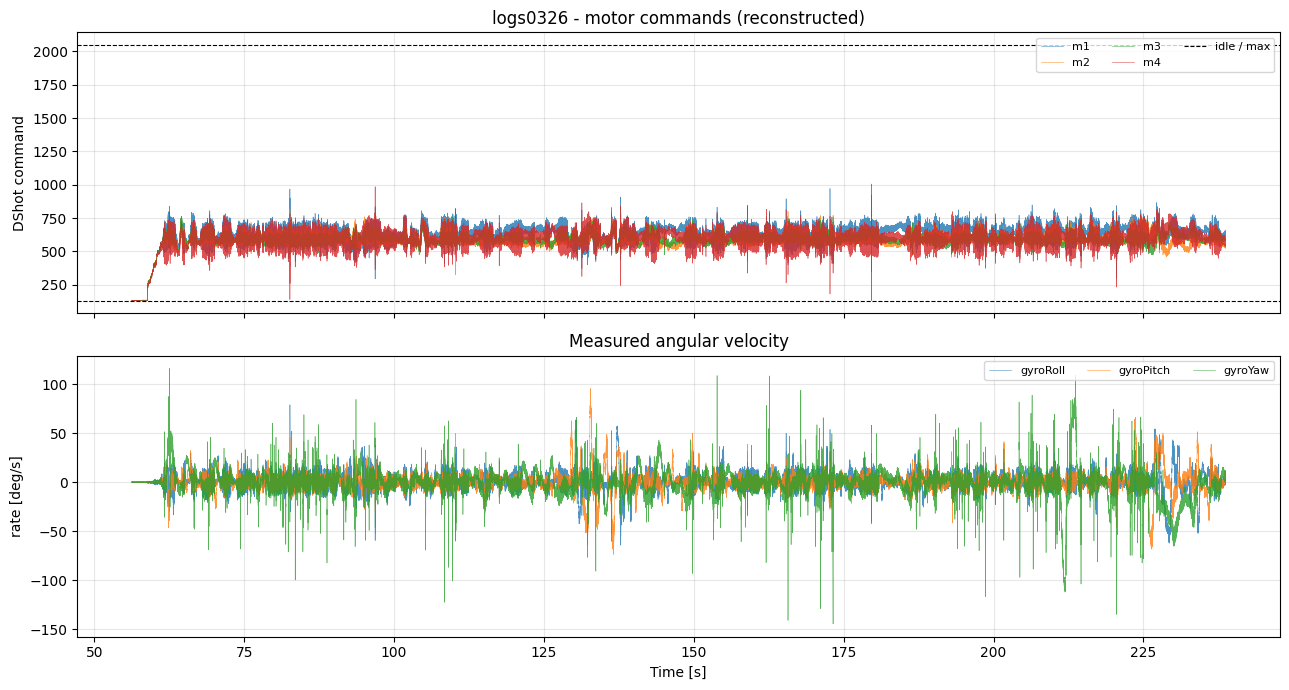

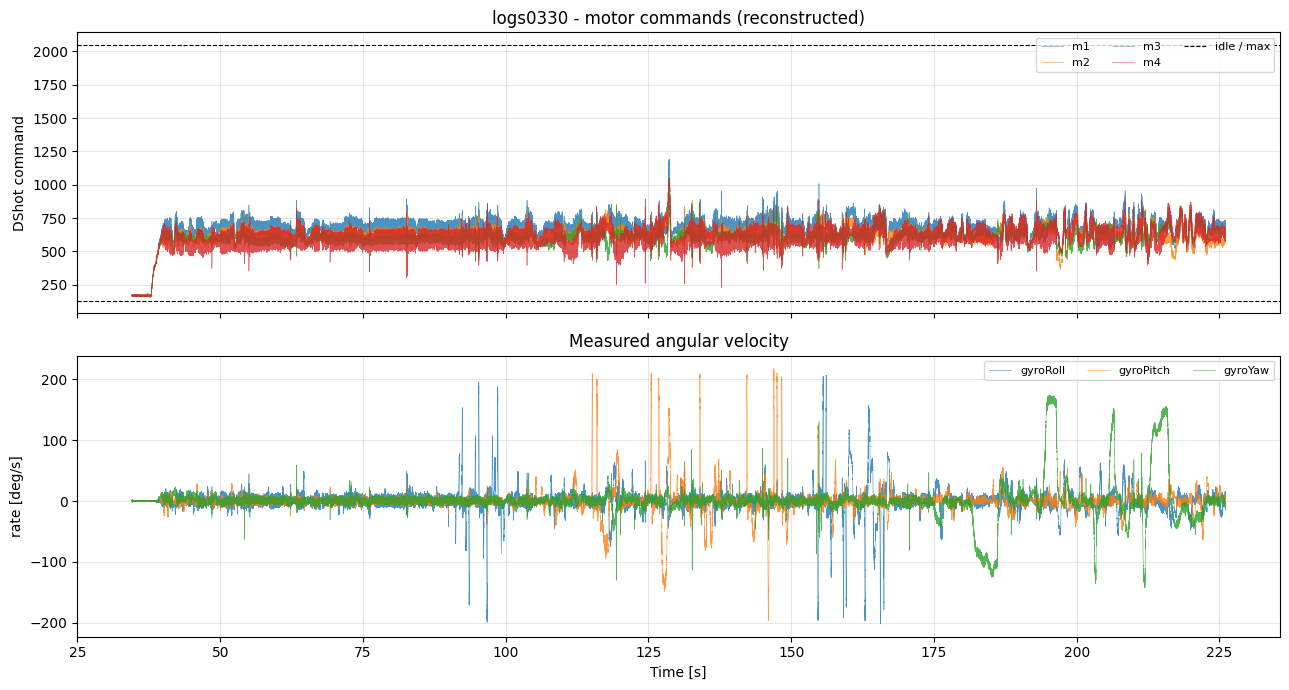

In [4]:
# ============================================================
# m1..m4 and gyro, full flight
# ============================================================

MOTOR_COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
GYRO_COLORS = {"Roll": "tab:blue", "Pitch": "tab:orange", "Yaw": "tab:green"}

for name, df in logs.items():

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    for m, c in zip(MOTORS, MOTOR_COLORS):
        ax1.plot(df["t"], df[m], lw=0.4, color=c, alpha=0.8, label=m)

    ax1.axhline(MOTOR_IDLE, color="k", ls="--", lw=0.8, label="idle / max")
    ax1.axhline(MOTOR_MAX, color="k", ls="--", lw=0.8)
    ax1.set_ylabel("DShot command")
    ax1.set_title(f"{name} - motor commands (reconstructed)")
    ax1.legend(loc="upper right", fontsize=8, ncol=3)

    for a in AXES:
        ax2.plot(df["t"], df[f"gyro{a}"], lw=0.4,
                 color=GYRO_COLORS[a], alpha=0.8, label=f"gyro{a}")

    ax2.set_ylabel("rate [deg/s]")
    ax2.set_xlabel("Time [s]")
    ax2.set_title("Measured angular velocity")
    ax2.legend(loc="upper right", fontsize=8, ncol=3)

    fig.tight_layout()
    plt.show()

### Zoom

Same two panels over 2 s, where the differential between the motors is readable.

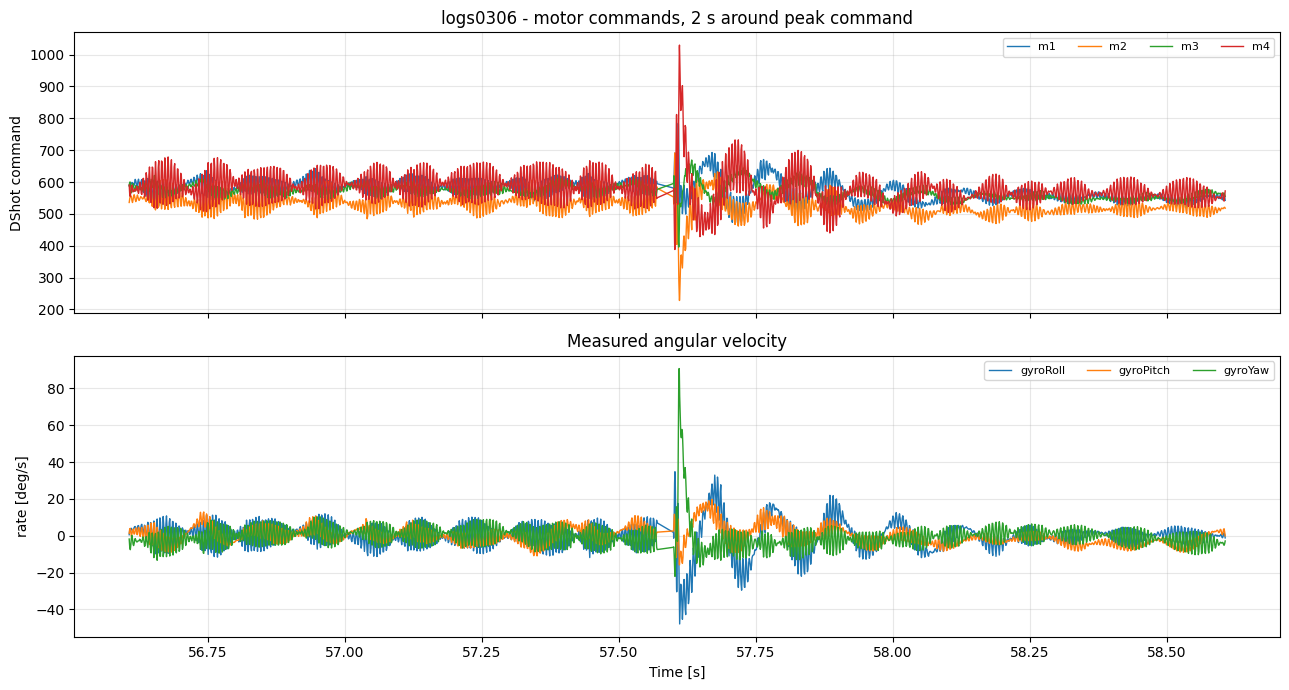

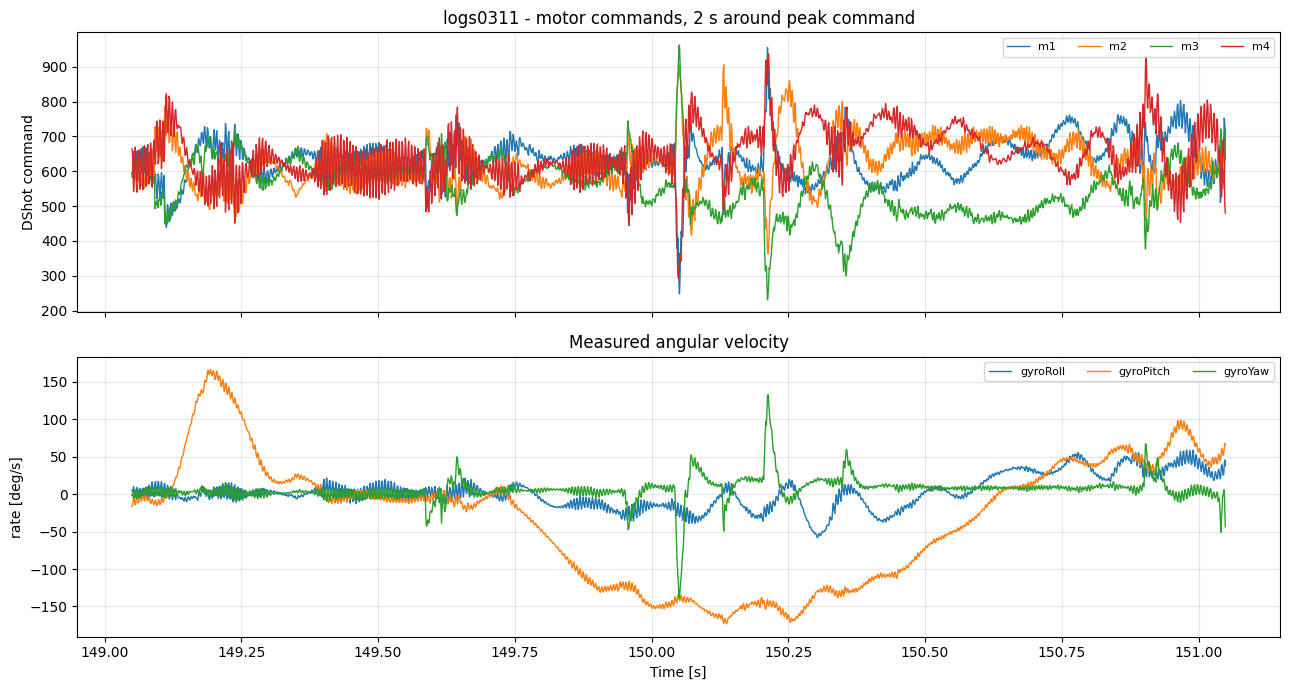

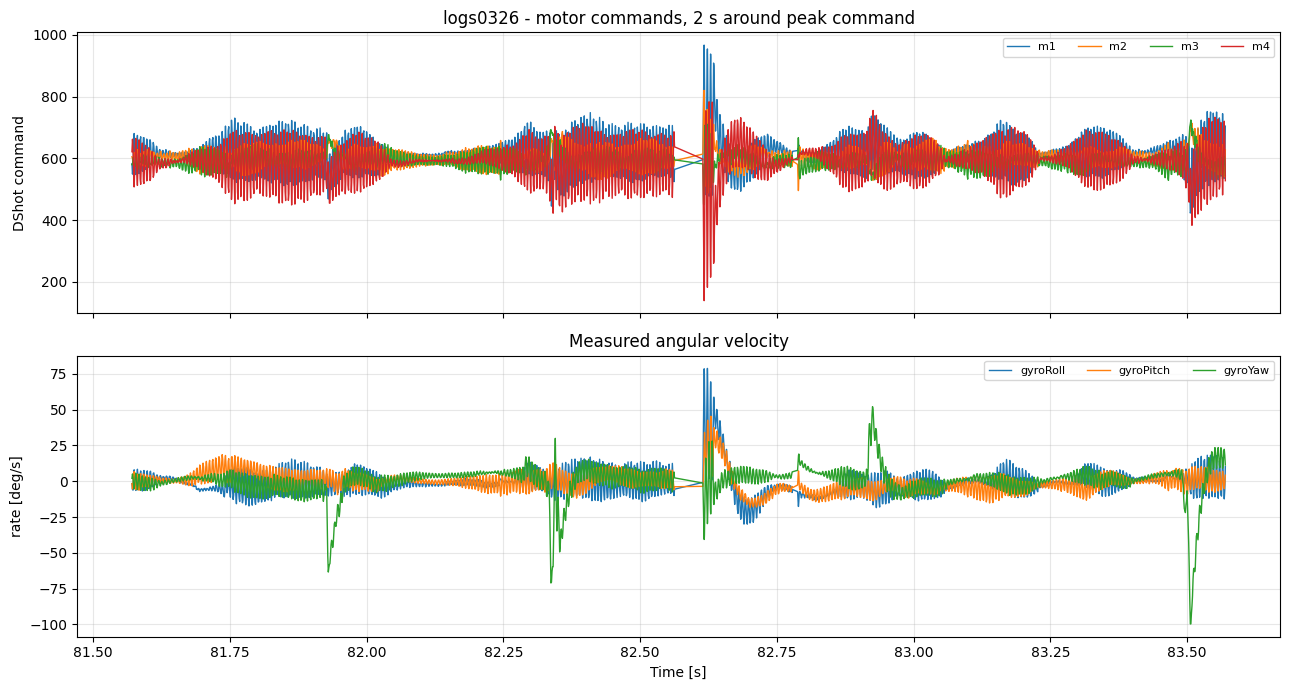

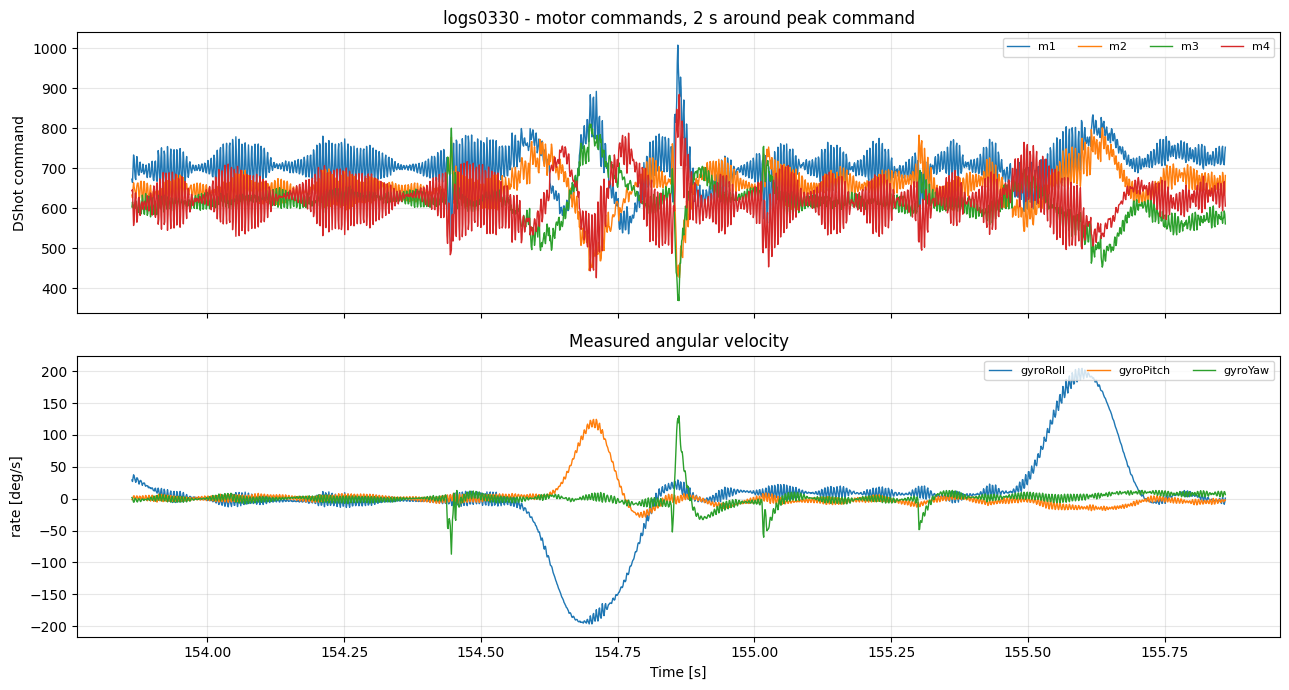

In [5]:
# ============================================================
# m1..m4 and gyro, 2 s window
# ============================================================

for name, df in logs.items():

    i = int(df[[f"u{a}" for a in AXES]].abs().max(axis=1).idxmax())
    half = int(WINDOW_S / 2 * 1000)
    sl = slice(max(0, i - half), min(len(df), i + half))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    for m, c in zip(MOTORS, MOTOR_COLORS):
        ax1.plot(df["t"][sl], df[m][sl], lw=1.0, color=c, label=m)

    ax1.set_ylabel("DShot command")
    ax1.set_title(f"{name} - motor commands, {WINDOW_S:g} s around peak command")
    ax1.legend(loc="upper right", fontsize=8, ncol=4)

    for a in AXES:
        ax2.plot(df["t"][sl], df[f"gyro{a}"][sl], lw=1.0,
                 color=GYRO_COLORS[a], label=f"gyro{a}")

    ax2.set_ylabel("rate [deg/s]")
    ax2.set_xlabel("Time [s]")
    ax2.set_title("Measured angular velocity")
    ax2.legend(loc="upper right", fontsize=8, ncol=3)

    fig.tight_layout()
    plt.show()